In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [3]:
df = pd.read_csv(r"C:/Users/Hp/Desktop/LP3/ML/emails.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
(5172, 3002)
Email No.     0
the           0
to            0
e

In [4]:
#Pre-process the dataset
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print(df.columns)

Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)


In [5]:

# Separate input features and target
X = df.drop(columns=['Email No.', 'Prediction'])
y = df['Prediction']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

Features shape: (5172, 3000)
Target shape: (5172,)
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [6]:
#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
#Implement KNN and SVM
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

# SVM
svm = LinearSVC()
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [8]:
#Evaluate performance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

def evaluate_model(name, y_test, y_pred):
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
    print(classification_report(y_test, y_pred))

evaluate_model("KNN", y_test, knn_pred)
evaluate_model("SVM", y_test, svm_pred)


 KNN
Accuracy: 0.8338164251207729
Precision: 0.6434977578475336
Recall: 0.9566666666666667
F1 Score: 0.7694369973190348
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


 SVM
Accuracy: 0.9333333333333333
Precision: 0.8347826086956521
Recall: 0.96
F1 Score: 0.8930232558139535
              precision    recall  f1-score   support

           0       0.98      0.92      0.95       735
           1       0.83      0.96      0.89       300

    accuracy                           0.93      1035
   macro avg       0.91      0.94      0.92      1035
weighted avg       0.94      0.93      0.93      1035



  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.833816   0.643498  0.956667  0.769437
1   SVM  0.933333   0.834783  0.960000  0.893023


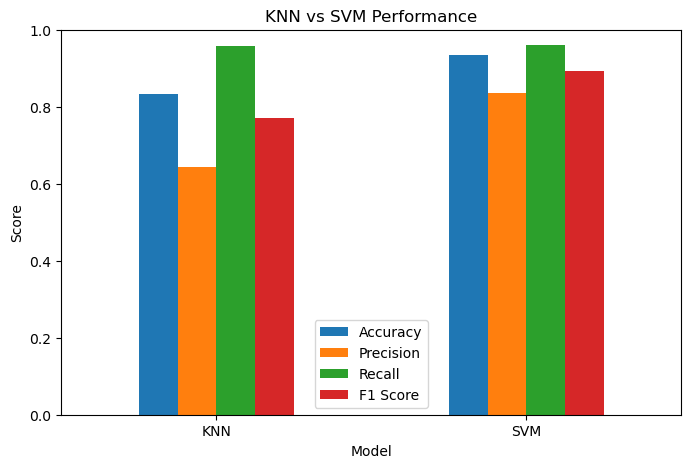

In [9]:
#Compare models
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    'Precision': [
        precision_score(y_test, knn_pred),
        precision_score(y_test, svm_pred)
    ],
    'Recall': [
        recall_score(y_test, knn_pred),
        recall_score(y_test, svm_pred)
    ],
    'F1 Score': [
        f1_score(y_test, knn_pred),
        f1_score(y_test, svm_pred)
    ]
})

print(results)

results.set_index('Model').plot(kind='bar', figsize=(8, 5))
plt.title("KNN vs SVM Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

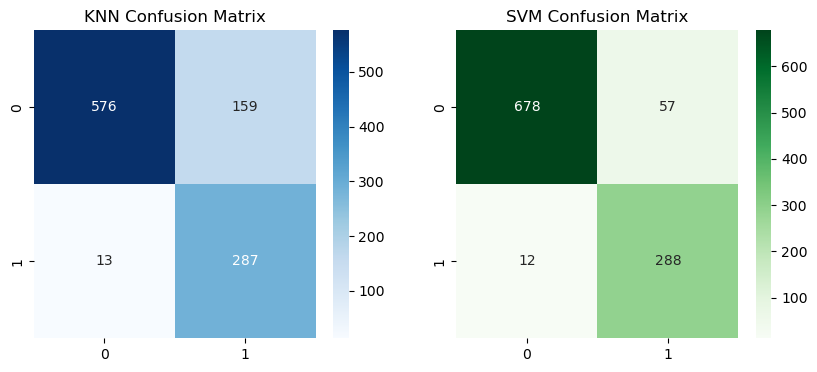

In [10]:
#Confusion matrices
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(y_test, knn_pred),
            annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("KNN Confusion Matrix")

sns.heatmap(confusion_matrix(y_test, svm_pred),
            annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("SVM Confusion Matrix")

plt.show()

In [12]:
# Test a new email using the existing numeric features
new_email = X_test[0].reshape(1, -1)

prediction = svm.predict(new_email)

if prediction[0] == 1:
    print("Spam Email")
else:
    print("Not Spam Email")

Spam Email
